# Streaming flights with Spark

A normal DataFrame is a **photo**: Spark reads the data once and the result does not change.
A **stream** is a **video**: new data keeps arriving and Spark keeps the answer up to date.

In this notebook new flights "take off" every two seconds:

```
flight_producer.py  --writes a file every 2 s-->  incoming_flights/  --Spark reads-->  tables and charts
```

- `flight_producer.py` is a small Python script. It picks random flights from `T_ONTIME_REPORTING.csv` and writes them to a JSON file, as if they had just departed.
- `incoming_flights/` is the folder where those files land. You can see it in the file browser on the left.
- Spark watches that folder and reads every new file.

## Step 0: start the producer

1. In JupyterLab open **File > New > Terminal**.
2. Type `python flight_producer.py` and press Enter.
3. Leave it running. A line appears every 2 seconds and a new file appears in `incoming_flights/`. Open one: each line is one flight.

Then come back here and run the cells from top to bottom. Times are in UTC, the clock of the container.

## 1. Start Spark

- `local[*]`: Spark runs inside this notebook and uses all the cores of this computer. The cluster workers cannot see the `incoming_flights` folder, so this lesson does not use them.
- `spark.sql.shuffle.partitions`: a `groupBy` splits its work into pieces. The default is 200 pieces, far too many for a few flights every two seconds: every update would be about 8 times slower.
- `setLogLevel("ERROR")`: hide Spark's technical warnings and keep only real errors.

Spark prints two red lines while it starts (`Setting default log level` and `NativeCodeLoader`). They are normal.

In [1]:
import time

import matplotlib.pyplot as plt
from IPython.display import clear_output
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder.appName("Flights streaming")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", 4)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "is ready")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/12 00:24:25 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Spark 3.3.3 is ready


## 2. A photo of the folder

First read the folder the normal way, with `spark.read`. The schema tells Spark the name and the type of each column, so it does not have to guess.

| column | meaning |
| --- | --- |
| `event_time` | when the flight departed |
| `flight` | flight number |
| `origin` | airport the flight left from |
| `origin_city` | city of that airport |
| `dest` | destination airport |
| `dep_delay` | departure delay in minutes (negative means it left early) |

In [2]:
schema = "event_time TIMESTAMP, flight INT, origin STRING, origin_city STRING, dest STRING, dep_delay DOUBLE"

photo = spark.read.schema(schema).json("incoming_flights")
photo.show(5)
print("flights in the folder right now:", photo.count())

+-------------------+------+------+-----------+----+---------+
|         event_time|flight|origin|origin_city|dest|dep_delay|
+-------------------+------+------+-----------+----+---------+
|2026-11-12 00:24:34|  2071|   MEM|Memphis, TN| ATL|     -7.0|
|2026-11-12 00:24:34|   392|   HOU|Houston, TX| DCA|      3.0|
|2026-11-12 00:24:34|  1642|   DAL| Dallas, TX| PHX|     -4.0|
|2026-11-12 00:24:34|  1964|   SEA|Seattle, WA| IAH|    -11.0|
|2026-11-12 00:24:34|  3745|   TUS| Tucson, AZ| SLC|     -2.0|
+-------------------+------+------+-----------+----+---------+
only showing top 5 rows

flights in the folder right now: 750


Run the cell above again after a few seconds. The count is bigger, because the producer has written more files. Every run takes a new photo.

## 3. A video of the folder

Change one word: `read` becomes `readStream`. Now Spark does not read the folder once. It keeps watching it.

In [3]:
flights = spark.readStream.schema(schema).json("incoming_flights")
print("Is it a stream?", flights.isStreaming)

Is it a stream? True


## 4. The stream fills a table

A stream has no end, so `flights.show()` would wait for ever. Instead you **start a query**. The query runs in the background: every time new files arrive it reads them (one *micro-batch*) and writes the result somewhere.

Here the result goes into a table in memory that we can look at whenever we like:

- `format("memory")`: keep the result in a table in memory
- `queryName("all_flights")`: the name of that table
- `outputMode("append")`: add the new rows and keep the old ones

A query that is stopped in the middle of a micro-batch makes Spark print a long error. `stop_queries()` waits for the current micro-batch to finish, then stops every running query.

In [4]:
def stop_queries():
    for q in spark.streams.active:
        while q.status["isTriggerActive"]:
            time.sleep(0.1)
        q.stop()

The next cell starts the query, counts the rows of the table every 5 seconds, then stops the query. It also calls `stop_queries()` before it starts, in case a query is still running from before, so you can run the cell again.

The first count is already large: the query starts with the files that were already in the folder. After that it reads only the new ones.

While a query runs, the **Structured Streaming** tab of the Spark UI at http://localhost:4040 shows its micro-batches.

In [5]:
stop_queries()

query = (
    flights.writeStream
    .format("memory")
    .queryName("all_flights")
    .outputMode("append")
    .start()
)

for i in range(6):
    time.sleep(5)
    print("after", (i + 1) * 5, "seconds:", spark.table("all_flights").count(), "flights in the table")

stop_queries()
spark.table("all_flights").orderBy(F.desc("event_time")).show(5)

after 5 seconds: 1383 flights in the table
after 10 seconds: 1451 flights in the table
after 15 seconds: 1585 flights in the table
after 20 seconds: 1668 flights in the table
after 25 seconds: 1771 flights in the table
after 30 seconds: 1860 flights in the table
+-------------------+------+------+---------------+----+---------+
|         event_time|flight|origin|    origin_city|dest|dep_delay|
+-------------------+------+------+---------------+----+---------+
|2026-11-12 00:25:30|  2522|   MSY|New Orleans, LA| ATL|    -11.0|
|2026-11-12 00:25:30|  3738|   SNA|  Santa Ana, CA| LAS|     10.0|
|2026-11-12 00:25:30|  5782|   DEN|     Denver, CO| ASE|     -2.0|
|2026-11-12 00:25:30|  5981|   JAC|    Jackson, WY| LAX|     -2.0|
|2026-11-12 00:25:30|  2921|   PHX|    Phoenix, AZ| CLT|      0.0|
+-------------------+------+------+---------------+----+---------+
only showing top 5 rows



## 5. Busiest airports

Now ask the stream a question: how many flights left from each airport? It is the same `groupBy` you use on a normal DataFrame.

In [6]:
by_airport = flights.groupBy("origin").agg(F.count("*").alias("departures"))

The answer changes with every new file, so this query uses `outputMode("complete")`: every micro-batch rewrites the whole result table.

The chart reads that table every 5 seconds, 12 times (about one minute). Watch the bars grow.

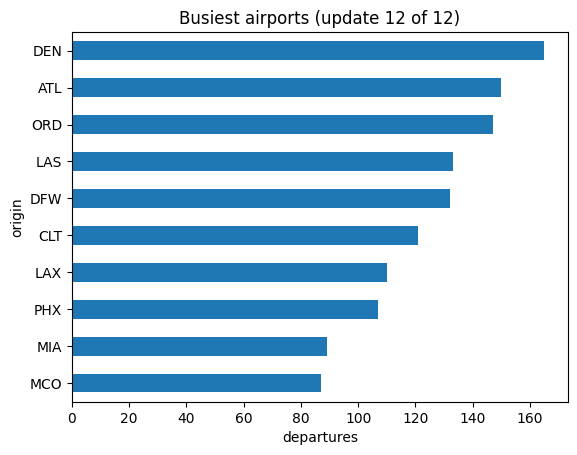

In [7]:
stop_queries()

query = (
    by_airport.writeStream
    .format("memory")
    .queryName("busiest_airports")
    .outputMode("complete")
    .start()
)

for i in range(12):
    time.sleep(5)
    top = spark.table("busiest_airports").orderBy(F.desc("departures")).limit(10).toPandas()
    clear_output(wait=True)
    if not top.empty:
        ax = top.sort_values("departures").plot.barh(x="origin", y="departures", legend=False)
        ax.set_title(f"Busiest airports (update {i + 1} of 12)")
        ax.set_xlabel("departures")
        plt.show()

stop_queries()

## 6. On time or late?

A flight counts as late when it leaves more than 15 minutes after its scheduled time. `F.when(...).otherwise(...)` adds a column with the answer, and `groupBy` counts each answer.

In [8]:
with_status = flights.withColumn(
    "status", F.when(F.col("dep_delay") > 15, "late").otherwise("on time")
)
by_status = with_status.groupBy("status").agg(F.count("*").alias("flights"))

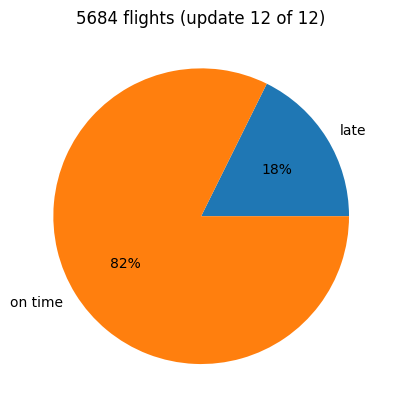

In [9]:
stop_queries()

query = (
    by_status.writeStream
    .format("memory")
    .queryName("on_time_or_late")
    .outputMode("complete")
    .start()
)

for i in range(12):
    time.sleep(5)
    status = spark.table("on_time_or_late").orderBy("status").toPandas()
    clear_output(wait=True)
    if not status.empty:
        ax = status.set_index("status")["flights"].plot.pie(autopct="%1.0f%%")
        ax.set_title(f"{status['flights'].sum()} flights (update {i + 1} of 12)")
        ax.set_ylabel("")
        plt.show()

stop_queries()

## 7. Time windows

So far every answer covers all the flights since the query started. Often the question is about *right now*: how many flights left in the last 30 seconds?

`F.window("event_time", "30 seconds")` puts every flight in a 30-second box, using the time it departed. Then we count the flights and average their delay in each box. The producer writes between 10 and 60 flights per file, so some boxes are busier than others.

The chart shows the last 10 windows. The bar on the right is the window that is still filling up.

In [10]:
by_window = flights.groupBy(F.window("event_time", "30 seconds")).agg(
    F.count("*").alias("departures"),
    F.round(F.avg("dep_delay"), 1).alias("avg_delay"),
)

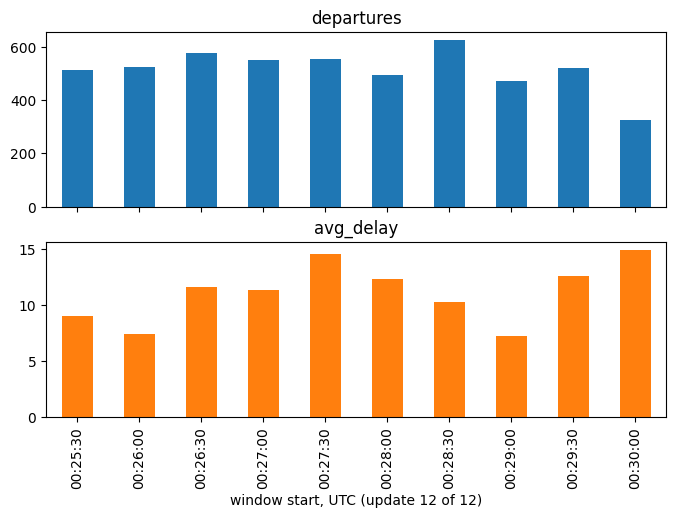

In [11]:
stop_queries()

query = (
    by_window.writeStream
    .format("memory")
    .queryName("flights_per_window")
    .outputMode("complete")
    .start()
)

for i in range(12):
    time.sleep(5)
    windows = (
        spark.table("flights_per_window")
        .orderBy("window.start")
        .select(F.date_format("window.start", "HH:mm:ss").alias("start"), "departures", "avg_delay")
        .toPandas()
        .tail(10)
    )
    clear_output(wait=True)
    if not windows.empty:
        windows.plot.bar(x="start", y=["departures", "avg_delay"], subplots=True, legend=False, figsize=(8, 5))
        plt.xlabel(f"window start, UTC (update {i + 1} of 12)")
        plt.show()

stop_queries()

## 8. Stop everything

Stop any query that is still running. Then go to the terminal and press **Ctrl+C** to stop the producer.

In [12]:
stop_queries()
print("queries still running:", len(spark.streams.active))

queries still running: 0


## What you saw

| idea | code |
| --- | --- |
| read a folder once (a photo) | `spark.read.schema(schema).json(folder)` |
| read a folder as a stream (a video) | `spark.readStream.schema(schema).json(folder)` |
| ask a question | the usual `groupBy`, `agg`, `withColumn`, `F.when` |
| run the question on the stream | `writeStream ... .start()` |
| keep every new row | `outputMode("append")` |
| rewrite the whole answer each time | `outputMode("complete")` |
| look at the answer | `spark.table(name)` |
| group by time | `F.window("event_time", "30 seconds")` |
| stop | `query.stop()`, between two micro-batches |

The question is written exactly as on a normal DataFrame. What changes is that Spark keeps answering it while new data arrives.

## Exercises

1. In section 5, count the flights per destination (`dest`) instead of per origin.
2. In section 6, call a flight late only when it leaves more than 60 minutes late. How does the pie change?
3. In section 7, change the window to 10 seconds. How many bars do you get in the same minute?

## Next level

- **Late data and watermarks**: what to do with a flight that arrives a minute after its window has closed.
- **Joins**: add the city and the coordinates of each airport from `airports.csv`, then draw the flights on a map.
- **SQL on a stream**: `flights.createOrReplaceTempView("flights")` and then `spark.sql(...)`.
- **Kafka**: a real message broker instead of a folder. The questions stay the same; only the source changes.